In [22]:
import math
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import openfermion as of
from openfermionpyscf import run_pyscf

This technique is taken from https://quantum-journal.org/papers/q-2025-04-01-1682/

In [2]:
ENERGY_ERR = 1.6e-3 # chemical accuracy in Ha

In [3]:
def thm4_M_formula(D, eta, eps, tau, theta):
    """Eq. (28): M = ceil( 2 [ (2.07/pi (ln 4D + gamma) + 1) / (eta - 2 eps) ]^2 [ ln ln(1/(tau eps)) + ln(1/theta) ] ).
    All logs are natural; gamma is the Euler-Mascheroni constant (additive, from H_D ~ ln D + gamma)."""
    assert eta > 2 * eps

    factor1_num = 2.07 / np.pi * (np.log(4 * D) + np.euler_gamma) + 1
    factor1_denom = eta - 2 * eps
    factor2 = np.log(np.log(1. / (tau * eps))) + np.log(1. / theta)
    return np.ceil(2 * (factor1_num / factor1_denom) ** 2 * factor2)

In [4]:
def W0(z):
    """Principal-branch Lambert W. scipy returns complex dtype even for real results, so take the real part."""
    w = scipy.special.lambertw(z, k=0)
    assert abs(w.imag) < 1e-12, f"W0({z}) is not real"
    return w.real


def eq7_beta(delta, eps):
    """Eq. (7): beta = max(1, W0(2/(pi eps^2)) / (4 sin^2 delta))."""
    return max(1., W0(2. / (np.pi * eps ** 2)) / (4 * np.sin(delta) ** 2))


def f_thm3(beta, x):
    """Eq. (26): f(beta, x) = -(ln x + beta) / W0(-[1 + ln(x)/beta] e^{-1}).
    The paper names the second argument eps, but it is a dummy variable; in Eq. (25) it is evaluated at
    x = min(1, 4 e^{-w(eps)/2}), NOT at the theorem's input eps."""
    return -(np.log(x) + beta) / W0(-(1 + np.log(x) / beta) * np.exp(-1))


def thm3_D_formula(delta, eps):
    """Eq. (25): D = 2 ceil( sqrt( f(beta, min(1, 4 e^{-w/2})) w ) ) + 1, with w = W0(18/(pi eps^2))."""
    beta = eq7_beta(delta, eps)
    w_eps = W0(18. / (np.pi * eps ** 2))
    x = min(1., 4. * np.exp(-w_eps / 2))
    return 2 * np.ceil(np.sqrt(f_thm3(beta, x) * w_eps)) + 1

In [13]:
def shot_count(energy_err, eta, ham_norm, theta=0.05, tau_safety=0.99):
    # theta is the failure probability (success probability 1 - theta).
    # Eq. (1): tau ||H|| < pi/2 (strict), so back off from the boundary by tau_safety.
    # delta is the precision in the rescaled (tau H) units, and the paper
    # relates the two via eps = delta / tau (Sec. 2; restated as delta = tau eps in the proof of Thm 4).
    tau = tau_safety * np.pi / (2. * ham_norm)
    eps = energy_err
    delta = tau * eps
    D = thm3_D_formula(delta, eps)
    return thm4_M_formula(D, eta, eps, tau, theta)

In [14]:
def hydrogen_chain_ham_norm(natoms, bond_distance=1.0):
    """Spectral norm of the JW-mapped H_n chain Hamiltonian (sto-3g)."""
    geometry = [("H", (0, 0, i * bond_distance)) for i in range(natoms)]
    molecule = of.MolecularData(geometry, basis="sto-3g", multiplicity=1, charge=natoms % 2)
    molecule = run_pyscf(molecule, run_scf=True, run_mp2=True, verbose=False)

    hamiltonian = of.jordan_wigner(of.get_fermion_operator(molecule.get_molecular_hamiltonian()))
    hamiltonian_matrix = of.linalg.get_sparse_operator(hamiltonian)
    # Spectral norm (largest |eigenvalue|), not the Frobenius norm that scipy.sparse.linalg.norm returns.
    return abs(scipy.sparse.linalg.eigsh(hamiltonian_matrix, k=1, which="LM", return_eigenvectors=False)[0])

In [15]:
natoms_list = [3, 4, 5, 6, 7]
ham_norms = {n: hydrogen_chain_ham_norm(n) for n in natoms_list}
for n, norm in ham_norms.items():
    print(f"H{n}: ||H|| = {norm:.4f} Ha")

H3: ||H|| = 1.5781 Ha
H4: ||H|| = 2.8706 Ha
H5: ||H|| = 4.3059 Ha
H6: ||H|| = 5.8511 Ha
H7: ||H|| = 7.4864 Ha


In [24]:
etas = np.linspace(0.25, 0.999, num=5)
# shot_counts = {
#     n: np.array([shot_count(ENERGY_ERR, eta, ham_norms[n]) for eta in etas])
#     for n in natoms_list
# }
records = []
for eta in etas:
    for n in natoms_list:
        shots = shot_count(ENERGY_ERR, eta, ham_norms[n])
        records.append((n, eta, shots))

df = pd.DataFrame.from_records(records, columns=["n", "eta", "shots"])

In [25]:
# colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # fixed categorical order

# fig, ax = plt.subplots(figsize=(6.5, 4))
# for n, color in zip(natoms_list, colors):
#     ax.plot(etas, shot_counts[n], color=color, linewidth=2, label=f"h$_{{{n}}}$")
#     # ax.annotate(f"h$_{{{n}}}$", (etas[-1], shot_counts[n][-1]), xytext=(4, 0),
#     #             textcoords="offset points", va="center", fontsize=9, color="0.3")
# ax.set_xlabel(r"ground-state overlap lower bound $\eta$")
# ax.set_ylabel("number of samples $m$")
# # ax.set_title(f"thm 4 sample count, $\\epsilon$ = {energy_err} ha, $\\vartheta$ = 0.1")
# ax.set_yscale("log")
# ax.grid(true, which="both", color="0.9", linewidth=0.8)
# for side in ("top", "right"):
#     ax.spines[side].set_visible(false)
# ax.legend(frameon=false)
# fig.tight_layout()
# # fig.savefig("data/m_vs_eta.pdf")
# plt.show()

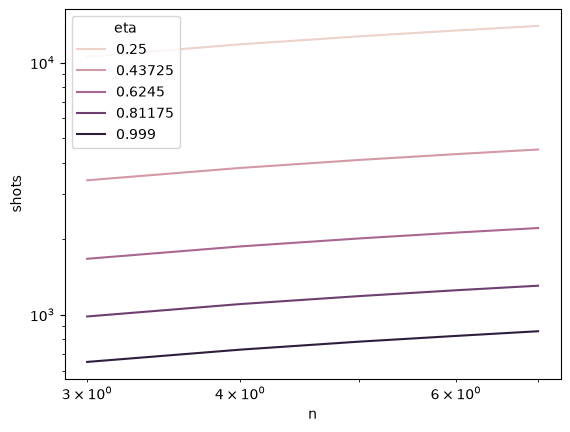

In [28]:
fig, ax = plt.subplots()
sns.lineplot(data=df, ax=ax, x="n", y="shots", hue="eta")
ax.set_yscale("log")
ax.set_xscale("log")

In [ ]:
# Theorem 4 gives M ~ (ln 4D + const)^2 * lnln(...) / (eta - 2 eps)^2, and D grows linearly with ||H||.
# ||H|| is roughly linear in n with an offset, so fit M = A * (ln(n - n0) + c)^2 per eta.
def log_sq_model(n, A, c, n0):
    return A * (np.log(n - n0) + c) ** 2

fit_records = []
for eta, g in df.groupby("eta"):
    n, M = g["n"].to_numpy(dtype=float), g["shots"].to_numpy()
    (A, c, n0), cov = scipy.optimize.curve_fit(log_sq_model, n, M, p0=[30., 8., 1.5], maxfev=50000)
    A_err, c_err, n0_err = np.sqrt(np.diag(cov))
    fit_records.append((eta, A, A_err, c, c_err, n0, n0_err, np.abs(M / log_sq_model(n, A, c, n0) - 1).max()))

fits = pd.DataFrame.from_records(
    fit_records, columns=["eta", "A", "A_err", "c", "c_err", "n0", "n0_err", "max_rel_err"])
fits

In [ ]:
colors = sns.color_palette("crest", n_colors=len(fits))  # sequential: eta is a magnitude
n_fine = np.linspace(min(natoms_list), max(natoms_list), 100)

fig, ax = plt.subplots(figsize=(8, 4.5))
for color, fit in zip(colors, fits.itertuples()):
    g = df[df["eta"] == fit.eta]
    ax.plot(g["n"], g["shots"], "o", color=color, markersize=6)
    ax.plot(n_fine, log_sq_model(n_fine, fit.A, fit.c, fit.n0), "-", color=color, linewidth=2,
            label=rf"$\eta$={fit.eta:.2f}: {fit.A:.1f} $(\ln(n - {fit.n0:.2f}) + {fit.c:.2f})^2$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(natoms_list, labels=[str(n) for n in natoms_list])
ax.minorticks_off()
ax.set_xlabel("Number of H atoms $n$")
ax.set_ylabel("Number of samples $M$")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5),
          title=r"Fit $M = A\,(\ln(n - n_0) + c)^2$")
fig.tight_layout()
plt.show()